In [19]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json


In [20]:
!pip install -q kaggle

In [21]:
!kaggle datasets download -d salader/dogs-vs-cats

Dataset URL: https://www.kaggle.com/datasets/salader/dogs-vs-cats
License(s): unknown
 98% 1.04G/1.06G [00:04<00:00, 218MB/s]
100% 1.06G/1.06G [00:04<00:00, 234MB/s]


In [22]:
import zipfile
zip_ref = zipfile.ZipFile('/content/dogs-vs-cats.zip','r')
zip_ref.extractall('/content')
zip_ref.close()

In [23]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense,Flatten,Conv2D,MaxPooling2D,Dropout,BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping

In [24]:
# Generators for loading large dataset
train_ds = keras.utils.image_dataset_from_directory(
    directory = '/content/train',
    labels='inferred',
    label_mode = 'int',
    batch_size=32,
    image_size=(256,256)
)
test_ds = keras.utils.image_dataset_from_directory(
    directory = '/content/test',
    labels='inferred',
    label_mode = 'int',
    batch_size=32,
    image_size=(256,256)
)

Found 20000 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.


In [25]:
# Normalizing the images
def process(image,label):
  image=tf.cast(image/255. , tf.float32)
  return image,label
train_ds = train_ds.map(process)
test_ds = test_ds.map(process)

In [26]:
# Creating custom CNN Model
model = Sequential()

model.add((Conv2D(32,kernel_size=(3,3),padding='valid',activation='relu',input_shape=(256,256,3))))
model.add(BatchNormalization())
model.add((MaxPooling2D(pool_size=(2,2),strides=2,padding='valid')))

model.add((Conv2D(64,kernel_size=(3,3),padding='valid',activation='relu')))
model.add(BatchNormalization())
model.add((MaxPooling2D(pool_size=(2,2),strides=2,padding='valid')))

model.add((Conv2D(128,kernel_size=(3,3),padding='valid',activation='relu')))
model.add(BatchNormalization())
model.add((MaxPooling2D(pool_size=(2,2),strides=2,padding='valid')))

model.add(Flatten())

model.add(Dense(128,activation='relu'))
model.add(Dense(64,activation='relu'))
model.add(Dropout(0.2))

model.add(Dense(1,activation='sigmoid'))

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [27]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 254, 254, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 125, 125, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 60, 60, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,193 (56.64 MB)

 Trainable params: 14,847,745 (56.64 MB)

 Non-trainable params: 448 (1.75 KB)

In [28]:
early_stopping = EarlyStopping(monitor='val_loss', patience=5,restore_best_weights=True,verbose=1)

In [29]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [30]:
hist = model.fit(train_ds,epochs=10,validation_data=test_ds,callbacks=[early_stopping])

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 66s 88ms/step - accuracy: 0.5817 - loss: 1.9624 - val_accuracy: 0.6948 - val_loss: 0.5879
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 61s 97ms/step - accuracy: 0.7140 - loss: 0.5577 - val_accuracy: 0.7350 - val_loss: 0.5244
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 69s 77ms/step - accuracy: 0.7826 - loss: 0.4734 - val_accuracy: 0.7738 - val_loss: 0.4913
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 86s 83ms/step - accuracy: 0.8117 - loss: 0.4194 - val_accuracy: 0.7790 - val_loss: 0.4804
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 48s 77ms/step - accuracy: 0.8519 - loss: 0.3400 - val_accuracy: 0.8098 - val_loss: 0.4787
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 52s 83ms/step - accuracy: 0.8914 - loss: 0.2658 - val_accuracy: 0.7764 - val_loss: 0.5646
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 79s 78ms/step - accuracy: 0.9307 - loss: 0.1791 - val_accuracy: 0.7830 - val_loss: 0.8250
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 85s 83ms/step - accuracy: 0.9418 - loss: 0.1589 - 

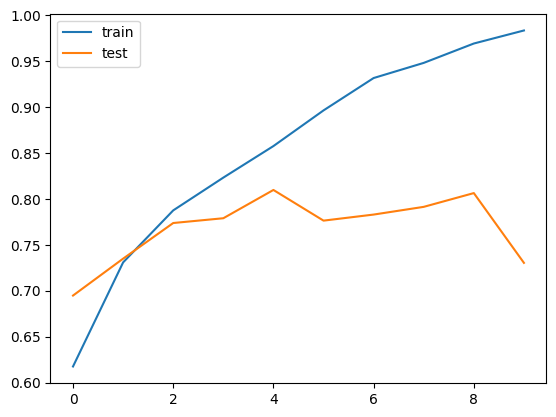

In [48]:
import matplotlib.pyplot as plt
plt.plot(hist.history['accuracy'],label='train')
plt.plot(hist.history['val_accuracy'],label='test')
plt.legend()
plt.show()

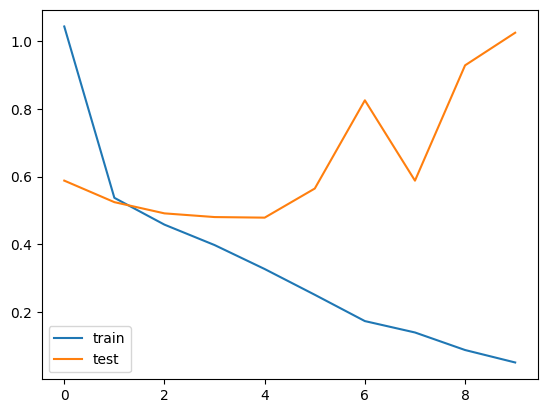

In [49]:
import matplotlib.pyplot as plt
plt.plot(hist.history['loss'],label='train')
plt.plot(hist.history['val_loss'],label='test')
plt.legend()
plt.show()

In [33]:
# Methods to reduce overfitting :
# 1. Data Augmentation
# 2. BatchNormalization
# 3. Dropout, EarlyStopping
# 4. L1/L2 Regularization
# 5. Reduce complexity
# 6. Add more data

img1 (6124, 4082, 3)


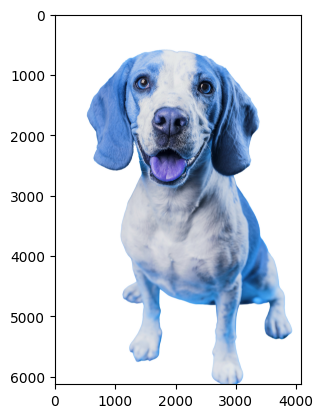

In [34]:
import cv2
test_img_1=cv2.imread('/content/dog.jpg')
plt.imshow(test_img_1)
print("img1",test_img_1.shape)

img2 (360, 540, 3)


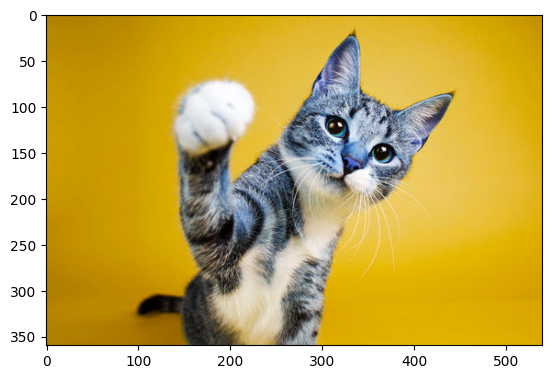

In [35]:
test_img_2=cv2.imread('/content/cat.jpg')
plt.imshow(test_img_2)
print("img2",test_img_2.shape)

In [36]:
# Resize the image to the desired dimensions
test_img_1 = cv2.resize(test_img_1, (256, 256))
test_input_1 = test_img_1.reshape((1,256,256,3))
print(model.predict(test_input_1))

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
[[1.7119501e-20]]


In [37]:
# Poor performance
test_img_2 = cv2.resize(test_img_2, (256, 256))
test_input_2 = test_img_2.reshape((1,256,256,3))
print(model.predict(test_input_2))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
[[1.]]


In [38]:
# 1. [Batch Norm, Dropout] accuracy: 0.9486 - loss: 0.1344 - val_accuracy: 0.8202 - val_loss: 0.6937
# 2. [Batch Norm, Dropout, Early stopping] accuracy: 0.9802 - loss: 0.0586 - val_accuracy: 0.8234 - val_loss: 0.8932
# 3. [           [same]                  ] accuracy: 0.9609 - loss: 0.1116 - val_accuracy: 0.8200 - val_loss: 0.9124

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import seaborn as sns
import matplotlib.pyplot as plt

# Example data
y_true = np.array([1, 0, 1, 1, 0, 0, 1, 0, 1, 0])  # True labels
y_pred = np.array([1, 0, 1, 0, 0, 1, 1, 0, 1, 0])  # Predicted labels
y_prob = np.array([0.9, 0.1, 0.8, 0.4, 0.2, 0.6, 0.7, 0.3, 0.85, 0.15])  # Predicted probabilities

# 1. Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:")
print(cm)

# Visualize Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.savefig('confusion_matrix.png')
plt.close()

# 2. Accuracy
accuracy = accuracy_score(y_true, y_pred)
print(f"Accuracy: {accuracy:.4f}")

# 3. Precision
precision = precision_score(y_true, y_pred)
print(f"Precision: {precision:.4f}")

# 4. Recall
recall = recall_score(y_true, y_pred)
print(f"Recall: {recall:.4f}")

# 5. F1-Score
f1 = f1_score(y_true, y_pred)
print(f"F1-Score: {f1:.4f}")

# 6. ROC-AUC
roc_auc = roc_auc_score(y_true, y_prob)
print(f"ROC-AUC: {roc_auc:.4f}")